**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from zipfile import ZipFile
from pathlib import Path


In [2]:
uploaded = files.upload()


Saving kaggel_weather_2013_to_2024.csv to kaggel_weather_2013_to_2024.csv


In [3]:
import io

file_name = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Перші 5 рядків датасету:")
display(df.head())


Перші 5 рядків датасету:


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


Підготовка даних

In [4]:
df["DATE"] = pd.to_datetime(df["DATE"])

df = df.sort_values(by="DATE")

df = df.drop(columns=["Unnamed: 0"], errors="ignore")

df = df.set_index("DATE")

display(df.head())

print("Dataset shape:", df.shape)
print("Index name:", df.index.name)



,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


Dataset shape: (3557, 27)
Index name: DATE


In [5]:
print("Інформація про датасет:")
df.info()

print("\nОписова статистика:")
display(df.describe())


Інформація про датасет:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             3557 non-null   object 
 13  Year                   3557 non-null   int64  
 14  month         

,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
mean,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,23.137475,1.783095,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,42.177066,4.009455,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,0.000000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622
max,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,45.830000,...,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303


In [6]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())



Missing values in each column:
tempmax                  0
tempmin                  0
temp                     0
feelslikemax             0
feelslikemin             0
feelslike                0
humidity                 0
precip                   0
precipprob               0
precipcover              0
windspeed                0
sealevelpressure         0
conditions               0
Year                     0
month                    0
dayofweek                0
dayofyear                0
year-2000                0
weekofyear               0
tempmax_humidity         0
tempmin_humidity         0
temp_humidity            0
feelslikemax_humidity    0
feelslikemin_humidity    0
feelslike_humidity       0
temp_range               0
heat_index               0
dtype: int64

Total missing values: 0


In [8]:
print(df.columns.tolist())

['tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'humidity', 'precip', 'precipprob', 'precipcover', 'windspeed', 'sealevelpressure', 'conditions', 'Year', 'month', 'dayofweek', 'dayofyear', 'year-2000', 'weekofyear', 'tempmax_humidity', 'tempmin_humidity', 'temp_humidity', 'feelslikemax_humidity', 'feelslikemin_humidity', 'feelslike_humidity', 'temp_range', 'heat_index']


Графік температури

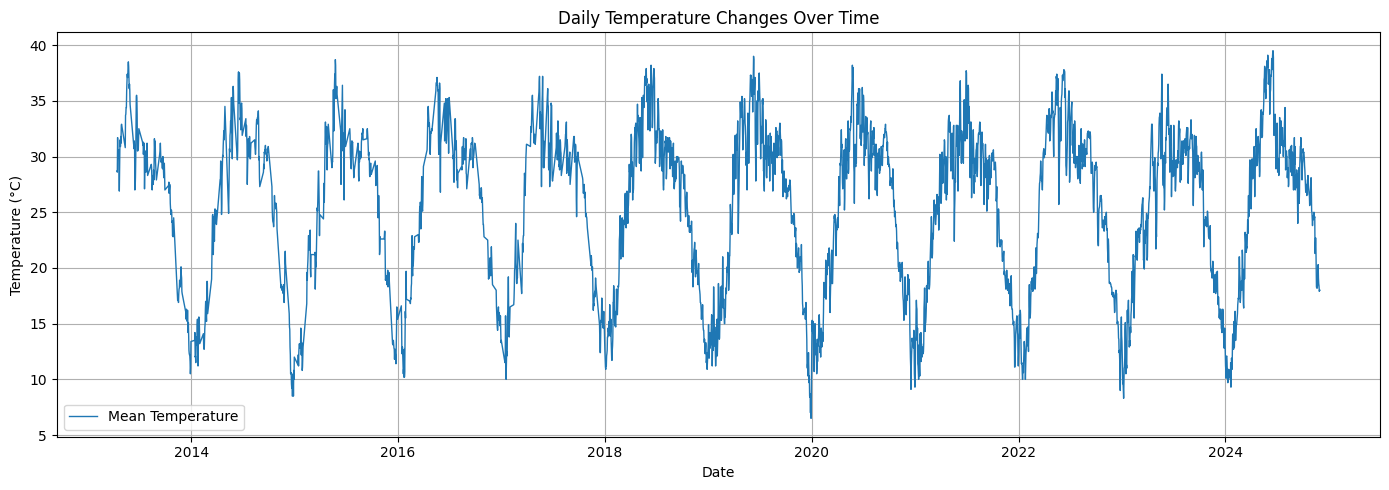

In [14]:
plt.figure(figsize=(14, 5))
plt.plot(df.index, df["temp"], label="Mean Temperature", linewidth=1)

plt.title("Daily Temperature Changes Over Time")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()




Ковзне середнє

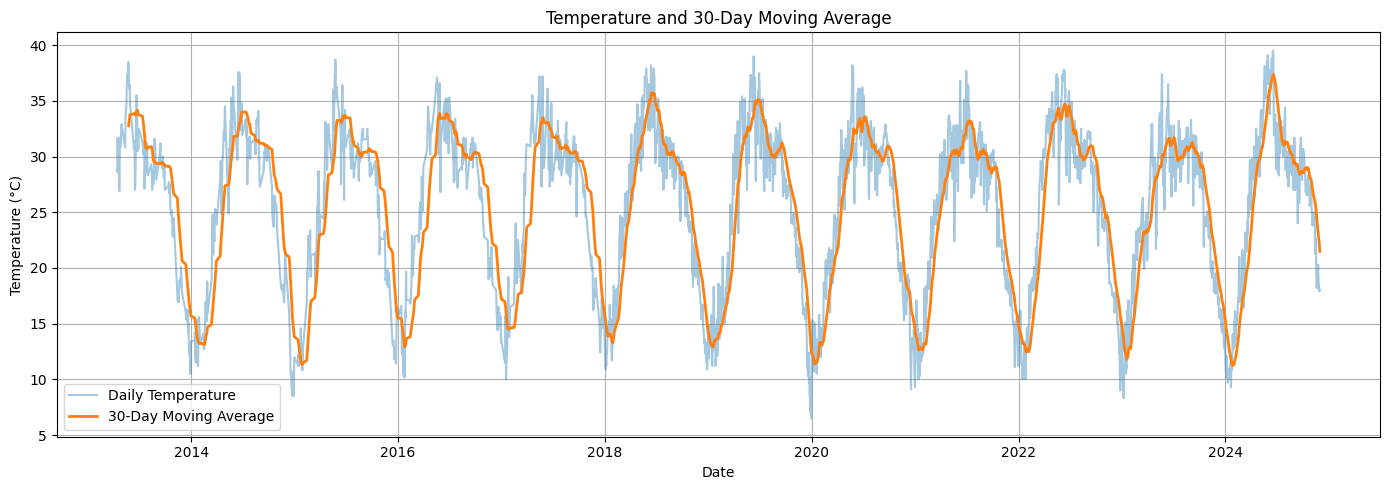

In [15]:
df["temperature_rolling_mean"] = df["temp"].rolling(window=30).mean()

plt.figure(figsize=(14, 5))
plt.plot(df.index, df["temp"], label="Daily Temperature", alpha=0.4)
plt.plot(df.index, df["temperature_rolling_mean"], label="30-Day Moving Average", linewidth=2)

plt.title("Temperature and 30-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



Розподіл температури

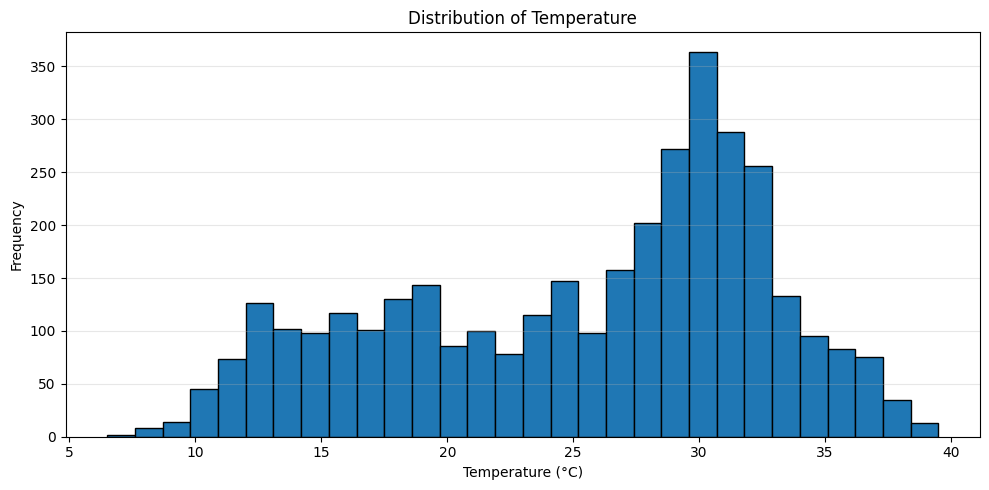

In [16]:
plt.figure(figsize=(10, 5))
plt.hist(df["temp"].dropna(), bins=30, edgecolor="black")

plt.title("Distribution of Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()




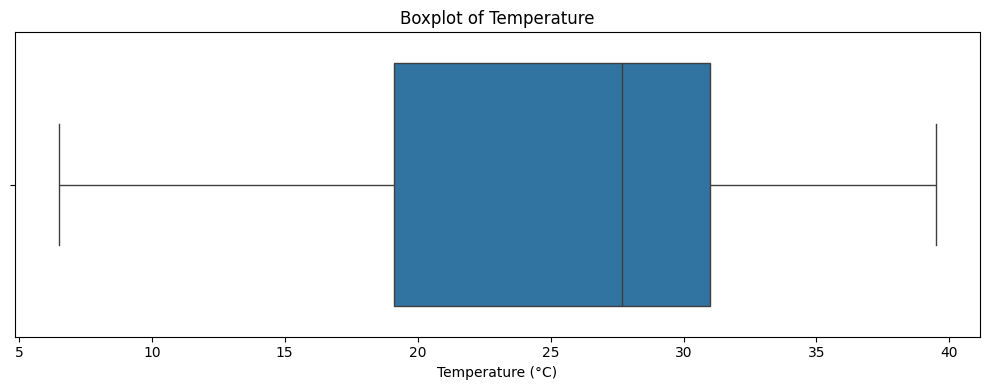

In [17]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["temp"])

plt.title("Boxplot of Temperature")
plt.xlabel("Temperature (°C)")
plt.tight_layout()
plt.show()




In [13]:
print(df.head())
print(df.index.name)

            tempmax  tempmin  temp  feelslikemax  feelslikemin  feelslike  \
DATE                                                                        
2013-04-14     37.7     23.1  28.7          35.4          23.1       28.1   
2013-04-15     37.5     21.1  28.6          35.3          21.1       28.0   
2013-04-16     40.1     21.9  31.7          37.5          21.9       30.4   
2013-04-17     36.4     21.0  29.9          34.0          21.0       28.5   
2013-04-18     37.5     21.7  30.6          35.2          21.7       29.2   

            humidity  precip  precipprob  precipcover  ...  weekofyear  \
DATE                                                   ...               
2013-04-14      39.7     2.0         100         4.17  ...          15   
2013-04-15      41.7     0.0           0         0.00  ...          16   
2013-04-16      30.7     0.0           0         0.00  ...          16   
2013-04-17      27.4     0.0           0         0.00  ...          16   
2013-04-18      

Аналіз автокореляції
ACF

PACF

<Figure size 1200x500 with 0 Axes>

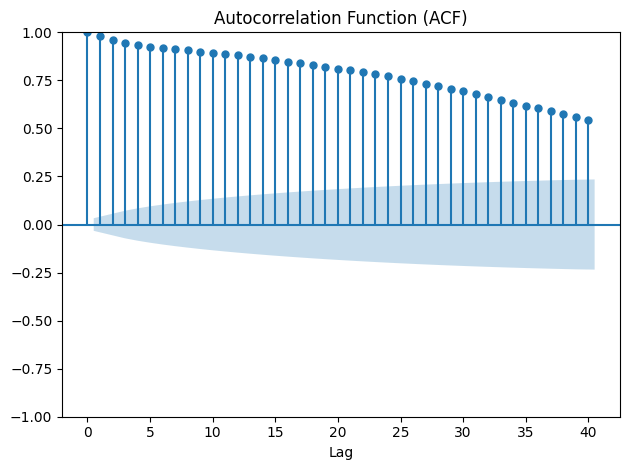

In [18]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12, 5))
plot_acf(df["temp"].dropna(), lags=40)
plt.title("Autocorrelation Function (ACF)")
plt.xlabel("Lag")
plt.tight_layout()
plt.show()



Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

<Figure size 1200x500 with 0 Axes>

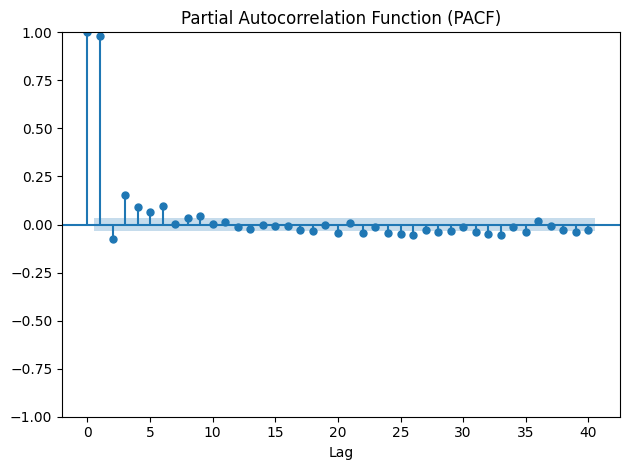

In [19]:
from statsmodels.graphics.tsaplots import plot_pacf

plt.figure(figsize=(12, 5))
plot_pacf(df["temp"].dropna(), lags=40, method="ywm")
plt.title("Partial Autocorrelation Function (PACF)")
plt.xlabel("Lag")
plt.tight_layout()
plt.show()



Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [20]:
ts = df["temp"].dropna().sort_index()

split_index = int(len(ts) * 0.8)

train = ts.iloc[:split_index]
test = ts.iloc[split_index:]

print("Total observations:", len(ts))
print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())



Total observations: 3557
Training observations: 2845
Testing observations: 712

Training period:
2013-04-14 00:00:00 to 2022-12-19 00:00:00

Testing period:
2022-12-20 00:00:00 to 2024-11-30 00:00:00


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [23]:
ts = df["temp"].dropna().sort_index()
ts = ts[~ts.index.duplicated(keep="first")]
ts = ts.asfreq("D")

ts = ts.interpolate(method="time")

split_index = int(len(ts) * 0.8)
train = ts.iloc[:split_index]
test = ts.iloc[split_index:]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Index frequency:", ts.index.freq)

Training observations: 3399
Testing observations: 850
Index frequency: <Day>


In [24]:

from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(train, order=(1, 1, 1))
arima_fit = arima_model.fit()

arima_forecast = arima_fit.forecast(steps=len(test))
arima_forecast.index = test.index

forecast_results = pd.DataFrame({
    "Actual Temperature": test,
    "Predicted Temperature": arima_forecast
})

display(forecast_results.head(10))



,Actual Temperature,Predicted Temperature
DATE,,
2022-08-04,29.4,30.718492
2022-08-05,27.9,30.746639
2022-08-06,30.2,30.736919
2022-08-07,27.6,30.740276
2022-08-08,30.1,30.739116
2022-08-09,32.0,30.739517
2022-08-10,32.5,30.739379
2022-08-11,29.6,30.739426
2022-08-12,31.2,30.739410


In [25]:
print(arima_fit.summary())


                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 3399
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -5476.397
Date:                Fri, 23 Oct 2026   AIC                          10958.794
Time:                        10:25:47   BIC                          10977.187
Sample:                    04-14-2013   HQIC                         10965.368
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3453      0.079     -4.387      0.000      -0.500      -0.191
ma.L1          0.4786      0.075      6.422      0.000       0.333       0.625
sigma2         1.4702      0.022     66.689      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

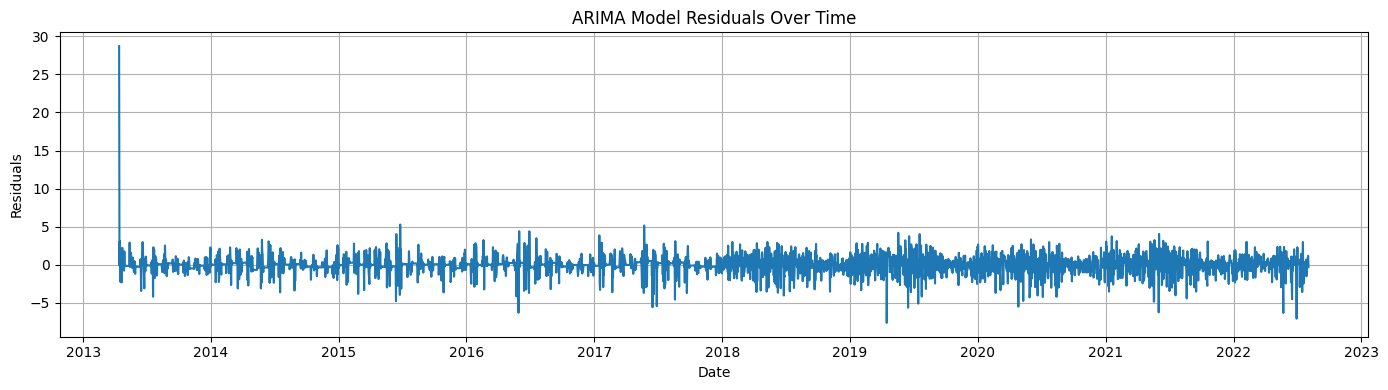

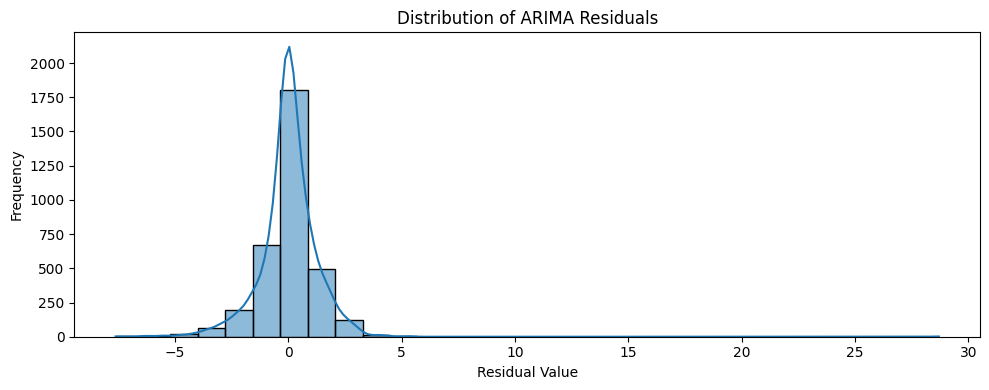

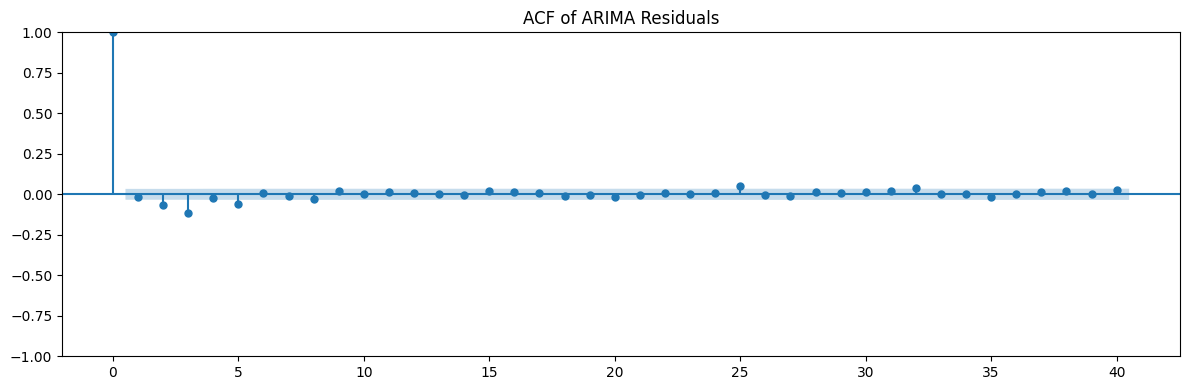

count    3399.000000
mean        0.008991
std         1.308653
min        -7.628864
25%        -0.463072
50%         0.021012
75%         0.606776
max        28.700000
dtype: float64


In [26]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt
import seaborn as sns

residuals = arima_fit.resid.dropna()

plt.figure(figsize=(14, 4))
plt.plot(residuals.index, residuals)
plt.title("ARIMA Model Residuals Over Time")
plt.xlabel("Date")
plt.ylabel("Residuals")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
sns.histplot(residuals, bins=30, kde=True)
plt.title("Distribution of ARIMA Residuals")
plt.xlabel("Residual Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(residuals, lags=40, ax=ax)
ax.set_title("ACF of ARIMA Residuals")
plt.tight_layout()
plt.show()

# Display residual statistics
print(residuals.describe())


In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(test, arima_forecast)
rmse = np.sqrt(mean_squared_error(test, arima_forecast))

def calculate_mape(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)

    nonzero_mask = actual != 0
    actual = actual[nonzero_mask]
    predicted = predicted[nonzero_mask]

    return np.mean(np.abs((actual - predicted) / actual)) * 100

mape = calculate_mape(test, arima_forecast)

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAPE: {mape:.2f}%")


MAE: 6.5059
RMSE: 8.7816
MAPE: 37.58%


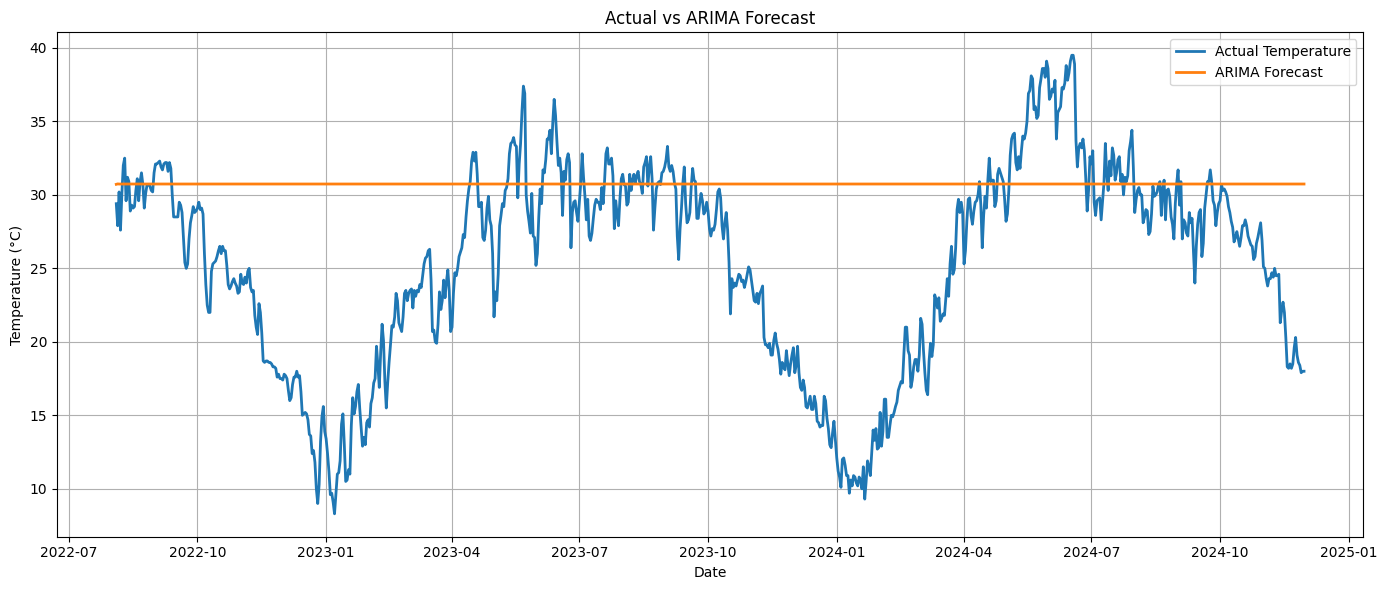

In [28]:
plt.figure(figsize=(14, 6))

plt.plot(test.index, test, label="Actual Temperature", linewidth=2)
plt.plot(
    test.index,
    arima_forecast,
    label="ARIMA Forecast",
    linewidth=2
)

plt.title("Actual vs ARIMA Forecast")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [29]:
prophet_data = pd.DataFrame({
    "ds": ts.index,
    "y": ts.values
})

split_index = int(len(prophet_data) * 0.8)

prophet_train = prophet_data.iloc[:split_index].copy()
prophet_test = prophet_data.iloc[split_index:].copy()

print("Training data:")
display(prophet_train.head())

print("Testing data:")
display(prophet_test.head())

print("Training shape:", prophet_train.shape)
print("Testing shape:", prophet_test.shape)


Training data:


,ds,y
0,2013-04-14,28.7
1,2013-04-15,28.6
2,2013-04-16,31.7
3,2013-04-17,29.9
4,2013-04-18,30.6


Testing data:


,ds,y
3399,2022-08-04,29.4
3400,2022-08-05,27.9
3401,2022-08-06,30.2
3402,2022-08-07,27.6
3403,2022-08-08,30.1


Training shape: (3399, 2)
Testing shape: (850, 2)


In [30]:
%pip install prophet


In [31]:
from prophet import Prophet

# Create and train the Prophet model
prophet_model = Prophet()
prophet_model.fit(prophet_train)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Прогноз

In [32]:
future = prophet_test[["ds"]].copy()

prophet_forecast = prophet_model.predict(future)

prophet_results = pd.DataFrame({
    "ds": prophet_test["ds"].values,
    "Actual Temperature": prophet_test["y"].values,
    "Predicted Temperature": prophet_forecast["yhat"].values
})

display(prophet_results.head(10))


,ds,Actual Temperature,Predicted Temperature
0,2022-08-04,29.4,30.472997
1,2022-08-05,27.9,30.501332
2,2022-08-06,30.2,30.522214
3,2022-08-07,27.6,30.534157
4,2022-08-08,30.1,30.675759
5,2022-08-09,32.0,30.877451
6,2022-08-10,32.5,30.966531
7,2022-08-11,29.6,30.987577
8,2022-08-12,31.2,31.000882
9,2022-08-13,30.9,30.992710


In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

actual = prophet_test["y"].to_numpy()
predicted = prophet_forecast["yhat"].to_numpy()

mae_prophet = mean_absolute_error(actual, predicted)
rmse_prophet = np.sqrt(mean_squared_error(actual, predicted))

def calculate_mape(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    nonzero_mask = actual != 0

    return np.mean(
        np.abs(
            (actual[nonzero_mask] - predicted[nonzero_mask])
            / actual[nonzero_mask]
        )
    ) * 100

mape_prophet = calculate_mape(actual, predicted)

print(f"Prophet MAE: {mae_prophet:.4f}")
print(f"Prophet RMSE: {rmse_prophet:.4f}")
print(f"Prophet MAPE: {mape_prophet:.2f}%")


Prophet MAE: 2.0669
Prophet RMSE: 2.6455
Prophet MAPE: 9.34%


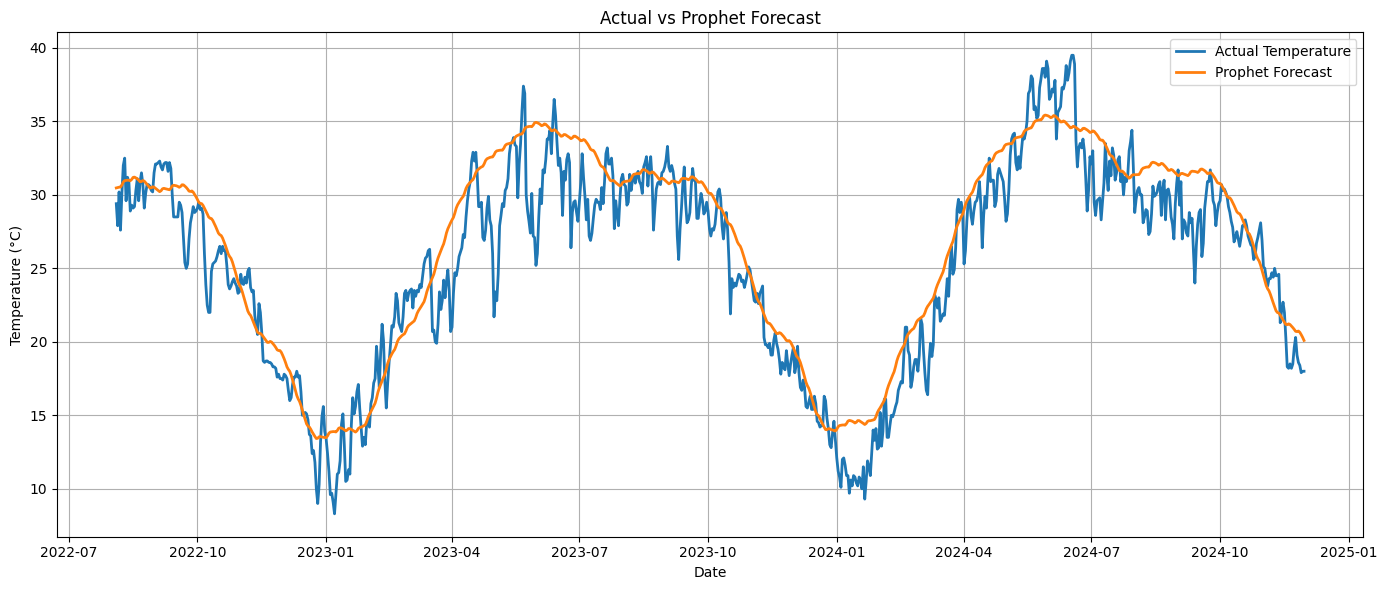

In [34]:
plt.figure(figsize=(14, 6))

plt.plot(
    prophet_test["ds"],
    prophet_test["y"],
    label="Actual Temperature",
    linewidth=2
)

plt.plot(
    prophet_test["ds"],
    prophet_forecast["yhat"],
    label="Prophet Forecast",
    linewidth=2
)

plt.title("Actual vs Prophet Forecast")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


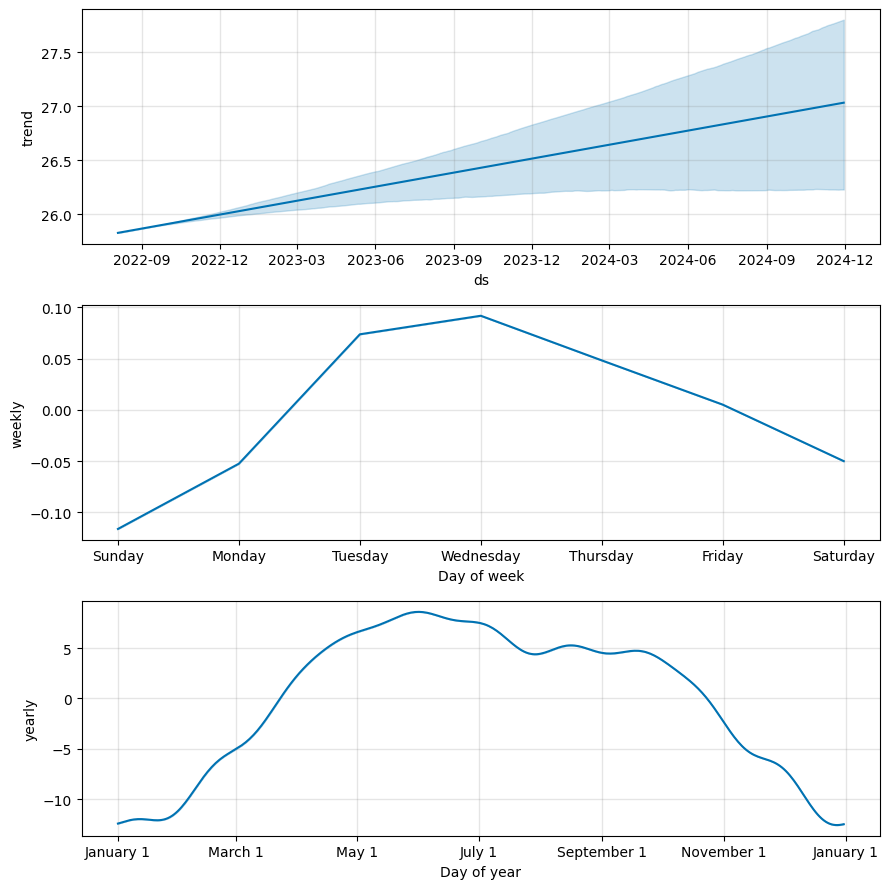

In [35]:
fig = prophet_model.plot_components(prophet_forecast)
plt.tight_layout()
plt.show()


ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [36]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np
import pandas as pd

ts = df["temp"].dropna().sort_index()
ts = ts[~ts.index.duplicated(keep="first")]
ts = ts.asfreq("D")
ts = ts.interpolate(method="time")

split_index = int(len(ts) * 0.8)
train = ts.iloc[:split_index]
test = ts.iloc[split_index:]

scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train.to_numpy().reshape(-1, 1))

sequence_length = 30

X_train = []
y_train = []

for i in range(sequence_length, len(train_scaled)):
    X_train.append(train_scaled[i - sequence_length:i, 0])
    y_train.append(train_scaled[i, 0])

X_train = np.array(X_train)
y_train = np.array(y_train)

X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)


X_train shape: (3369, 30, 1)
y_train shape: (3369,)


In [37]:
all_scaled = scaler.transform(ts.to_numpy().reshape(-1, 1))

X_test = []
y_test = []

for i in range(split_index, len(all_scaled)):
    X_test.append(all_scaled[i - sequence_length:i, 0])
    y_test.append(all_scaled[i, 0])

X_test = np.array(X_test).reshape(-1, sequence_length, 1)
y_test = np.array(y_test).reshape(-1, 1)

print("Training sequences:", X_train.shape[0])
print("Testing sequences:", X_test.shape[0])
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


Training sequences: 3369
Testing sequences: 850
X_test shape: (850, 30, 1)
y_test shape: (850, 1)


In [39]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

lstm_model = Sequential([
    LSTM(50, input_shape=(sequence_length, 1)),
    Dropout(0.2),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)


In [40]:
history = lstm_model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)


Epoch 1/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 0.0173 - mae: 0.0943 - val_loss: 0.0043 - val_mae: 0.0521
Epoch 2/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0071 - mae: 0.0660 - val_loss: 0.0040 - val_mae: 0.0481
Epoch 3/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0065 - mae: 0.0629 - val_loss: 0.0041 - val_mae: 0.0476
Epoch 4/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0062 - mae: 0.0613 - val_loss: 0.0036 - val_mae: 0.0457
Epoch 5/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0057 - mae: 0.0584 - val_loss: 0.0036 - val_mae: 0.0449
Epoch 6/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0053 - mae: 0.0568 - val_loss: 0.0034 - val_mae: 0.0444
Epoch 7/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0053 - mae: 0.0561 - val_loss: 0.0035 - val_mae: 0.0436
Epoch 8/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0051 - mae: 0.0550 - val_loss: 0.0032 - val_mae: 0.0425
Epoch 9/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0048 - mae: 

In [41]:
lstm_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,355 (122.48 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 20,904 (81.66 KB)

In [42]:
lstm_predictions_scaled = lstm_model.predict(X_test)

lstm_predictions = scaler.inverse_transform(lstm_predictions_scaled)
lstm_actual = scaler.inverse_transform(y_test)

print("Predictions shape:", lstm_predictions.shape)
print("Actual values shape:", lstm_actual.shape)

print("First 10 predictions:")
print(lstm_predictions[:10].flatten())


27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Predictions shape: (850, 1)
Actual values shape: (850, 1)
First 10 predictions:
[29.479193 29.231684 28.493145 28.84242  28.107948 28.558668 29.57115
 30.444942 29.921196 30.156088]


In [43]:
lstm_test_dates = test.index

lstm_results = pd.DataFrame({
    "Date": lstm_test_dates,
    "Actual Temperature": lstm_actual.flatten(),
    "Predicted Temperature": lstm_predictions.flatten()
})

display(lstm_results.head(10))


,Date,Actual Temperature,Predicted Temperature
0,2022-08-04,29.4,29.479193
1,2022-08-05,27.9,29.231684
2,2022-08-06,30.2,28.493145
3,2022-08-07,27.6,28.842421
4,2022-08-08,30.1,28.107948
5,2022-08-09,32.0,28.558668
6,2022-08-10,32.5,29.571150
7,2022-08-11,29.6,30.444942
8,2022-08-12,31.2,29.921196
9,2022-08-13,30.9,30.156088


In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae_lstm = mean_absolute_error(
    lstm_actual.flatten(),
    lstm_predictions.flatten()
)

rmse_lstm = np.sqrt(mean_squared_error(
    lstm_actual.flatten(),
    lstm_predictions.flatten()
))

def calculate_mape(actual, predicted):
    actual = np.asarray(actual).flatten()
    predicted = np.asarray(predicted).flatten()

    nonzero_mask = actual != 0

    return np.mean(
        np.abs(
            (actual[nonzero_mask] - predicted[nonzero_mask])
            / actual[nonzero_mask]
        )
    ) * 100

mape_lstm = calculate_mape(
    lstm_actual.flatten(),
    lstm_predictions.flatten()
)

print(f"LSTM MAE: {mae_lstm:.4f}")
print(f"LSTM RMSE: {rmse_lstm:.4f}")
print(f"LSTM MAPE: {mape_lstm:.2f}%")


LSTM MAE: 1.2922
LSTM RMSE: 1.6167
LSTM MAPE: 5.48%


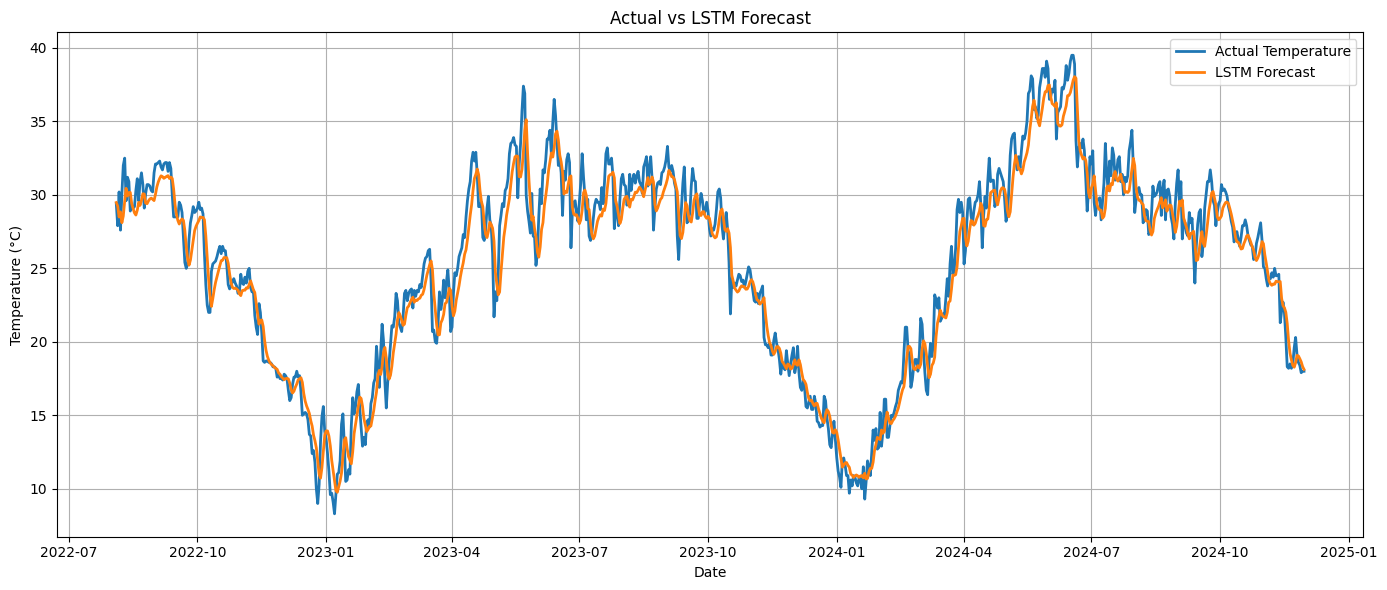

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    lstm_test_dates,
    lstm_actual.flatten(),
    label="Actual Temperature",
    linewidth=2
)

plt.plot(
    lstm_test_dates,
    lstm_predictions.flatten(),
    label="LSTM Forecast",
    linewidth=2
)

plt.title("Actual vs LSTM Forecast")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Порівняння моделей

In [46]:
comparison = pd.DataFrame({
    "Model": ["ARIMA", "Prophet", "LSTM"],
    "MAE": [mae, mae_prophet, mae_lstm],
    "RMSE": [rmse, rmse_prophet, rmse_lstm],
    "MAPE (%)": [mape, mape_prophet, mape_lstm]
})

comparison = comparison.sort_values(by="RMSE").reset_index(drop=True)

display(comparison.round(4))


,Model,MAE,RMSE,MAPE (%)
0,LSTM,1.2922,1.6167,5.4817
1,Prophet,2.0669,2.6455,9.3423
2,ARIMA,6.5059,8.7816,37.5804


In [47]:
best_mae = comparison.loc[comparison["MAE"].idxmin(), "Model"]
best_rmse = comparison.loc[comparison["RMSE"].idxmin(), "Model"]
best_mape = comparison.loc[comparison["MAPE (%)"].idxmin(), "Model"]

print("Best model by MAE:", best_mae)
print("Best model by RMSE:", best_rmse)
print("Best model by MAPE:", best_mape)

average_rank = comparison[["MAE", "RMSE", "MAPE (%)"]].rank().mean(axis=1)
best_overall = comparison.loc[average_rank.idxmin(), "Model"]

print("Best overall model based on average metric rank:", best_overall)

Best model by MAE: LSTM
Best model by RMSE: LSTM
Best model by MAPE: LSTM
Best overall model based on average metric rank: LSTM


## Висновок

Висновок: У ході роботи було проведено аналіз часового ряду температури, досліджено його закономірності та побудовано моделі прогнозування ARIMA, Prophet і LSTM. Якість моделей оцінювалася за метриками MAE, RMSE та MAPE. Найкращою вважається модель, яка має найменші значення цих показників. За результатами порівняння модель LSTM продемонструвала найвищу точність прогнозування температури на тестовій вибірці.
